In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_tea_snacks _1_.csv")
df.head()

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


In [ ]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(100, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   student_id    100 non-null    object
 1   gender        100 non-null    object
 2   age_group     100 non-null    object
 3   prefers_tea   100 non-null    object
 4   tea_type      77 non-null     object
 5   snack_choice  100 non-null    object
 6   cups_per_day  100 non-null    int64 
dtypes: int64(1), object(6)
memory usage: 5.6+ KB
None
student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64


Q1

In [ ]:
tea_counts = df["tea_type"].value_counts()
print(tea_counts)
print("Most preferred tea type:", tea_counts.idxmax())

tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64
Most preferred tea type: Green


Green tea is the most preferred tea type (29 students), ahead of Doodh Patti (25) and Black (23).

Q2

In [ ]:
avg_cups = df.groupby("gender")["cups_per_day"].mean().round(2)
print(avg_cups)

gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64


Males drink slightly more tea than females, averaging 3.0 cups per day compared with 2.6.

Q3

snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


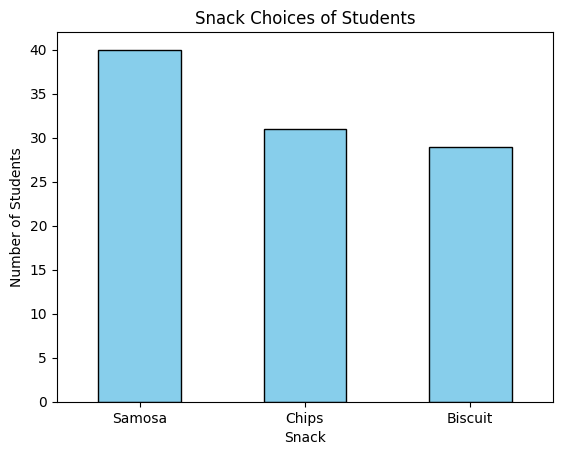

In [ ]:
snack_counts = df["snack_choice"].value_counts()
print(snack_counts)

snack_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Snack Choices of Students")
plt.xlabel("Snack")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

Samosa is the most popular snack (40 students), followed by Chips (31) and Biscuit (29).

Q4

prefers_tea  No  Yes
age_group           
18-20        19   20
21-23        17   15
24-26        13   16
prefers_tea    No   Yes
age_group              
18-20        48.7  51.3
21-23        53.1  46.9
24-26        44.8  55.2


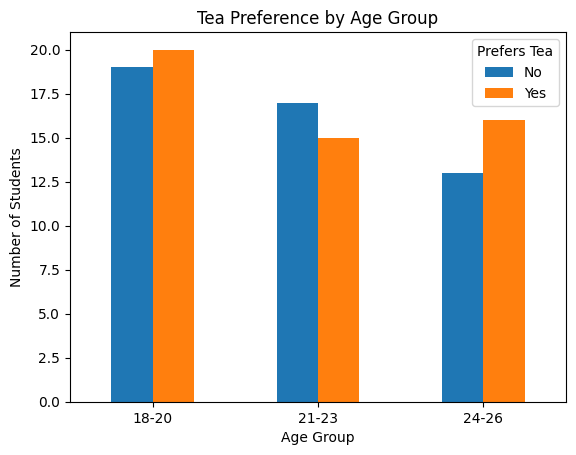

In [ ]:
# Counts
tea_by_age = pd.crosstab(df["age_group"], df["prefers_tea"])
print(tea_by_age)

# Percentages (fairer, since the groups are different sizes)
tea_by_age_pct = (pd.crosstab(df["age_group"], df["prefers_tea"], normalize="index") * 100).round(1)
print(tea_by_age_pct)

# Chart
tea_by_age.plot(kind="bar")
plt.title("Tea Preference by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.legend(title="Prefers Tea")
plt.show()

The 24–26 age group has the highest share of tea lovers (55.2%), and the 21–23 group has the lowest (46.9%). The 18–20 group sits in between (51.3%).

Q5

In [ ]:
no_tea = (df["prefers_tea"] == "No").sum()
print("Students who don't drink tea:", no_tea)

Students who don't drink tea: 49


49 students don't drink tea. Some of them still report cups per day, which suggests the data isn't fully consistent.